# Preprocesamiento de Imágenes

Juan Diego Solís Martínez - 23720  
Diego Oswaldo Flores Rivas - 23714  
Victor Manuel Pérez Chávez - 23731

**Objetivo de este notebook:** documentar y ejecutar todas las transformaciones que se le aplican
a las imágenes del dataset antes de entrenar los modelos. Las decisiones tomadas aquí
(resolución, normalización, partición) son las que alimentarán directamente el pipeline de
entrenamiento del notebook `03-deep-learning-models.ipynb`.

> **Contexto:** el EDA (`01-eda-lab3.ipynb`) estableció que el dataset contiene 87,000 imágenes
> `.jpg` de 200×200 px en RGB balanceadas en 29 clases, y que se construirá una
> partición estratificada propia 70/15/15 dado que el test original de Kaggle tiene solo 1 imagen
> por clase.


## 1. Configuración del entorno


In [1]:
import os
import random
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from PIL import Image, ImageFilter
from sklearn.model_selection import train_test_split

# Semilla global
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Rutas
DATA_DIR  = Path("./archive")
TRAIN_DIR = DATA_DIR / "asl_alphabet_train" / "asl_alphabet_train"
TEST_DIR  = DATA_DIR / "asl_alphabet_test"  / "asl_alphabet_test"

# Parámetros de preprocesamiento
TARGET_SIZE = (64, 64) # resolución objetivo
SAMPLE_PER_CLASS = 800 # muestra de trabajo para visualizaciones

CLASSES = sorted([d.name for d in TRAIN_DIR.iterdir() if d.is_dir()])
print(f"Clases encontradas ({len(CLASSES)}): {CLASSES}")
print(f"Resolución objetivo : {TARGET_SIZE}")


Clases encontradas (29): ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']
Resolución objetivo : (64, 64)


## 2. Inventario de archivos y construcción de la partición

Se reconstruye el listado completo de rutas (igual que en el EDA) y se aplica la partición
estratificada 70/15/15.


In [2]:
# Inventario completo de archivos
files_per_class = {
    cls: list((TRAIN_DIR / cls).iterdir())
    for cls in CLASSES
}

registros = [
    {"path": str(f), "clase": cls}
    for cls, files in files_per_class.items()
    for f in files
]
df_all = pd.DataFrame(registros)
print(f"Total de imágenes: {len(df_all):,}")

# Partición estratificada 70 / 15 / 15
train_df, temp_df = train_test_split(
    df_all, test_size=0.30, stratify=df_all["clase"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["clase"], random_state=SEED
)

print(f"Train : {len(train_df):,} imágenes ({len(train_df)/len(df_all):.1%})")
print(f"Val   : {len(val_df):,} imágenes ({len(val_df)/len(df_all):.1%})")
print(f"Test  : {len(test_df):,} imágenes ({len(test_df)/len(df_all):.1%})")

# Guardar los splits para reutilizarlos en el notebook de modelado
splits = {"train": train_df, "val": val_df, "test": test_df}
with open("splits.pkl", "wb") as f:
    pickle.dump(splits, f)
print("\nSplits guardados en splits.pkl")


Total de imágenes: 87,000
Train : 60,900 imágenes (70.0%)
Val   : 13,050 imágenes (15.0%)
Test  : 13,050 imágenes (15.0%)

Splits guardados en splits.pkl


**Observación:** la partición replica exactamente lo definido en el EDA. El archivo `splits.pkl`
persiste los índices de train/val/test para que el notebook de modelado use exactamente los mismos
conjuntos para garantizar reproducibilidad y evitar que cualquier imagen de val o test
contamine el entrenamiento.


## 3. Paso 1 — Reducción de resolución (resize 200×200 → 64×64)

El EDA mostró que las imágenes originales son de 200×200 px. Entonces, reducirlas a 64×64 representa
una reducción de ~9.8× en número de píxeles por imagen, lo cual:

- Hace manejable el entrenamiento.
- Conserva la señal visual para reconocer la forma general de la mano.

Se usa **interpolación bicúbica** (`Image.BICUBIC`) para el downscale, porque preserva los bordes
y contornos de la mano que la interpolación más simple, a un costo computacional
muy bajo dado que el resize ocurre una sola vez antes del entrenamiento.


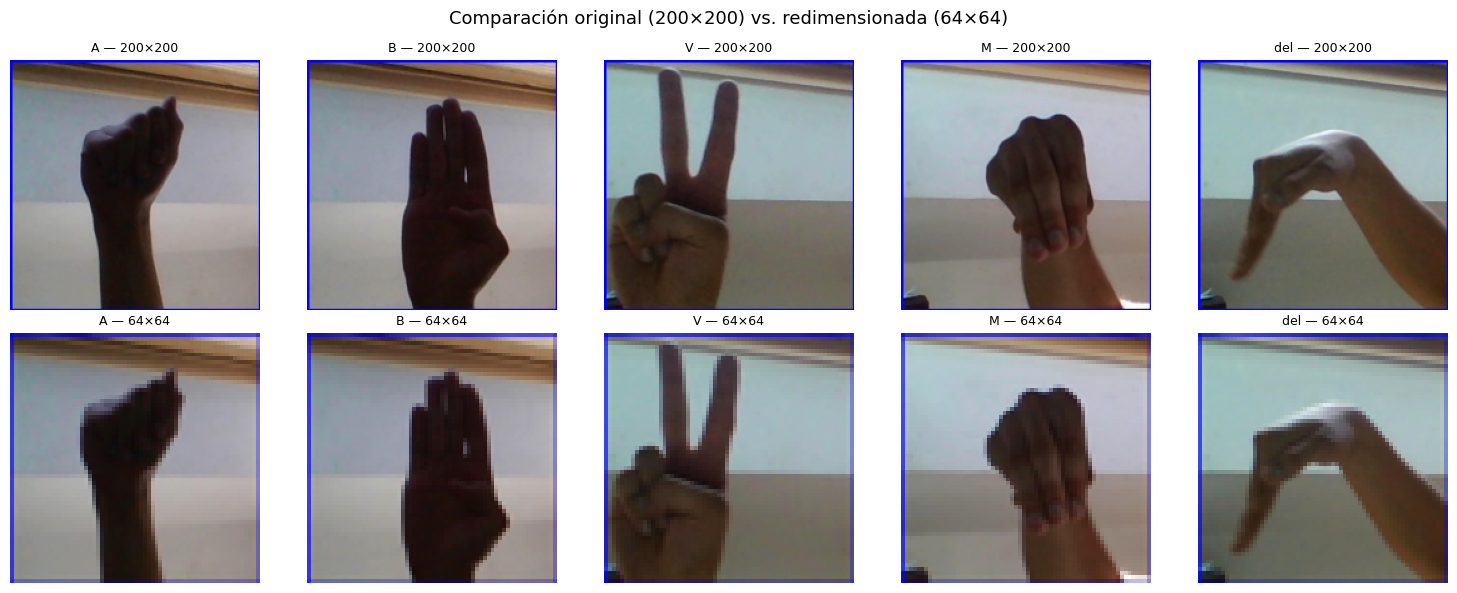

Tamaño original : (200, 200, 3)
Tamaño tras resize: (64, 64, 3)


In [3]:
# Abre una imagen y la redimensiona a size con interpolación bicúbica
def resize_image(path, size=TARGET_SIZE):
    with Image.open(path) as img:
        return img.resize(size, Image.BICUBIC)

# Visualización comparativa: original vs. redimensionada
sample_paths = [
    files_per_class[cls][0] for cls in ["A", "B", "V", "M", "del"]
]

fig, axes = plt.subplots(2, len(sample_paths), figsize=(len(sample_paths) * 3, 6))

for col, path in enumerate(sample_paths):
    original = Image.open(path)
    resized  = resize_image(path)
    cls_name = Path(path).parent.name

    axes[0, col].imshow(original)
    axes[0, col].set_title(f"{cls_name} — 200×200", fontsize=9)
    axes[0, col].axis("off")

    axes[1, col].imshow(resized)
    axes[1, col].set_title(f"{cls_name} — 64×64", fontsize=9)
    axes[1, col].axis("off")

fig.suptitle("Comparación original (200×200) vs. redimensionada (64×64)", fontsize=13)
plt.tight_layout()
plt.show()

print(f"Tamaño original : {np.array(Image.open(sample_paths[0])).shape}")
print(f"Tamaño tras resize: {np.array(resize_image(sample_paths[0])).shape}")


**Observación:** la reducción a 64×64 preserva la forma general de la mano y la postura de los
dedos, que es la señal que el modelo debe aprender.

## 4. Paso 2 — Normalización de valores de píxel

Las redes neuronales convergen más rápido y de forma más estable cuando las entradas están en un
rango numérico acotado y centrado. Se aplica la normalización estándar para imágenes RGB:

$$x_{\text{norm}} = \frac{x}{255.0}$$

Esto lleva cada canal de `[0, 255]` a `[0.0, 1.0]`. No se usa normalización por media/std del
dataset (estilo ImageNet) porque:

1. El dataset tiene fondo uniforme; la media global estaría sesgada por ese color y no
   representaría bien la distribución de la región de la mano.
2. La normalización `÷255` es suficiente para este problema y evita tener que calcular
   estadísticas sobre las 87,000 imágenes antes de poder entrenar.


In [4]:
# Pipeline completo de preprocesamiento para una imagen:
# 1. Abrir en RGB
# 2. Resize a TARGET_SIZE con interpolación bicúbica
# 3. Convertir a array float32
# 4. Normalizar a [0, 1]
# Retorna: ndarray de shape (H, W, 3) con dtype float32
def preprocess_image(path, size=TARGET_SIZE):
    with Image.open(path) as img:
        img = img.convert("RGB").resize(size, Image.BICUBIC)
    arr = np.array(img, dtype=np.float32) / 255.0
    return arr

# Verificación del rango y dtype
sample_arr = preprocess_image(sample_paths[0])
print(f"Shape del tensor preprocesado : {sample_arr.shape}")
print(f"dtype                         : {sample_arr.dtype}")
print(f"Rango de valores              : [{sample_arr.min():.4f}, {sample_arr.max():.4f}]")
print(f"Media global                  : {sample_arr.mean():.4f}")
print(f"Desviación estándar           : {sample_arr.std():.4f}")


Shape del tensor preprocesado : (64, 64, 3)
dtype                         : float32
Rango de valores              : [0.0275, 0.8745]
Media global                  : 0.4526
Desviación estándar           : 0.2237


## 5. Inspección visual de canales RGB y conversión a escala de grises

Se descompone una imagen representativa en sus tres canales para entender qué aporta cada uno.
Esta inspección ayuda a decidir si conviene trabajar con imágenes a color o en escala de grises:

**Decisión adoptada:** se trabaja en **RGB** para los modelos CNN, ya que el contraste
color-de-piel vs. fondo-verde puede ser una señal adicional útil. Para el modelo fully-connected
(notebook siguiente) se evaluará también la versión en escala de grises para reducir la
dimensionalidad del vector de entrada.


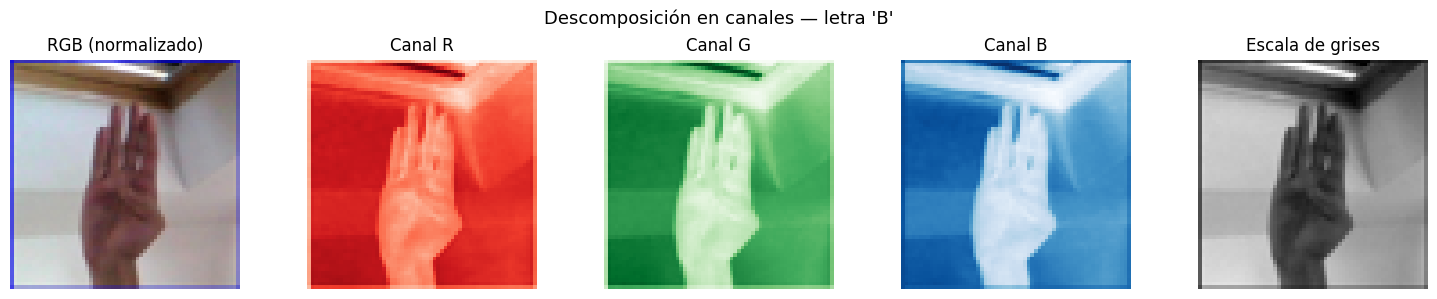

Shape RGB  : (64, 64, 3)  → 12288 valores
Shape Gray : (64, 64)    → 4096 valores


In [5]:
ejemplo_path = files_per_class["B"][10]  # letra B como ejemplo representativo
ejemplo_arr  = preprocess_image(ejemplo_path)  # ya normalizado

fig, axes = plt.subplots(1, 5, figsize=(15, 3))

# Imagen RGB completa
axes[0].imshow(ejemplo_arr)
axes[0].set_title("RGB (normalizado)")
axes[0].axis("off")

# Canal R
axes[1].imshow(ejemplo_arr[:, :, 0], cmap="Reds")
axes[1].set_title("Canal R")
axes[1].axis("off")

# Canal G
axes[2].imshow(ejemplo_arr[:, :, 1], cmap="Greens")
axes[2].set_title("Canal G")
axes[2].axis("off")

# Canal B
axes[3].imshow(ejemplo_arr[:, :, 2], cmap="Blues")
axes[3].set_title("Canal B")
axes[3].axis("off")

# Escala de grises
gray_arr = 0.299 * ejemplo_arr[:,:,0] + 0.587 * ejemplo_arr[:,:,1] + 0.114 * ejemplo_arr[:,:,2]
axes[4].imshow(gray_arr, cmap="gray")
axes[4].set_title("Escala de grises")
axes[4].axis("off")

plt.suptitle("Descomposición en canales — letra 'B'", fontsize=13)
plt.tight_layout()
plt.show()

print(f"Shape RGB  : {ejemplo_arr.shape}  → {ejemplo_arr.shape[0]*ejemplo_arr.shape[1]*3} valores")
print(f"Shape Gray : {gray_arr.shape}    → {gray_arr.shape[0]*gray_arr.shape[1]} valores")


**Observación:** el canal verde (G) captura principalmente el fondo y aporta poco contraste
sobre la mano. Los canales rojo (R) y azul (B) muestran mejor la silueta de los dedos.
La imagen en escala de grises combina los tres canales de forma ponderada y sigue mostrando
la forma de la mano.


## 6. Verificación estadística del pipeline sobre una muestra

Antes de construir el generador de datos para el entrenamiento, se verifica que el pipeline
completo (resize + normalización) produce tensores con las propiedades esperadas sobre una muestra
de imágenes de todas las clases.


In [6]:
# Procesar una muestra de 20 imágenes por clase para verificar estadísticas
rng = random.Random(SEED)
N_CHECK = 20

means_per_class  = {}
stds_per_class   = {}

for cls in CLASSES:
    paths_sample = rng.sample(files_per_class[cls], N_CHECK)
    arrs = np.stack([preprocess_image(p) for p in paths_sample])
    means_per_class[cls] = arrs.mean()
    stds_per_class[cls]  = arrs.std()

df_stats = pd.DataFrame({
    "clase" : list(means_per_class.keys()),
    "media" : list(means_per_class.values()),
    "std"   : list(stds_per_class.values()),
})

print("Estadísticas de píxeles normalizados por clase (muestra de 20 imgs/clase):")
print(df_stats.to_string(index=False))
print(f"\nMedia global: {df_stats['media'].mean():.4f} ± {df_stats['media'].std():.4f}")
print(f"Std global  : {df_stats['std'].mean():.4f} ± {df_stats['std'].std():.4f}")


Estadísticas de píxeles normalizados por clase (muestra de 20 imgs/clase):
  clase    media      std
      A 0.539439 0.238984
      B 0.513489 0.247007
      C 0.533196 0.244260
      D 0.512723 0.240786
      E 0.520864 0.230678
      F 0.483837 0.246399
      G 0.519901 0.251222
      H 0.483310 0.236830
      I 0.502795 0.250363
      J 0.505360 0.233925
      K 0.536753 0.256834
      L 0.560211 0.240507
      M 0.516618 0.250598
      N 0.500156 0.238367
      O 0.567873 0.231285
      P 0.527639 0.239723
      Q 0.536461 0.238442
      R 0.549839 0.202734
      S 0.531034 0.227504
      T 0.511317 0.252953
      U 0.534592 0.202862
      V 0.524358 0.202542
      W 0.538428 0.211042
      X 0.481626 0.218555
      Y 0.518125 0.231075
      Z 0.503332 0.231957
    del 0.488028 0.245841
nothing 0.530140 0.240885
  space 0.488940 0.224678

Media global: 0.5193 ± 0.0225
Std global  : 0.2348 ± 0.0151


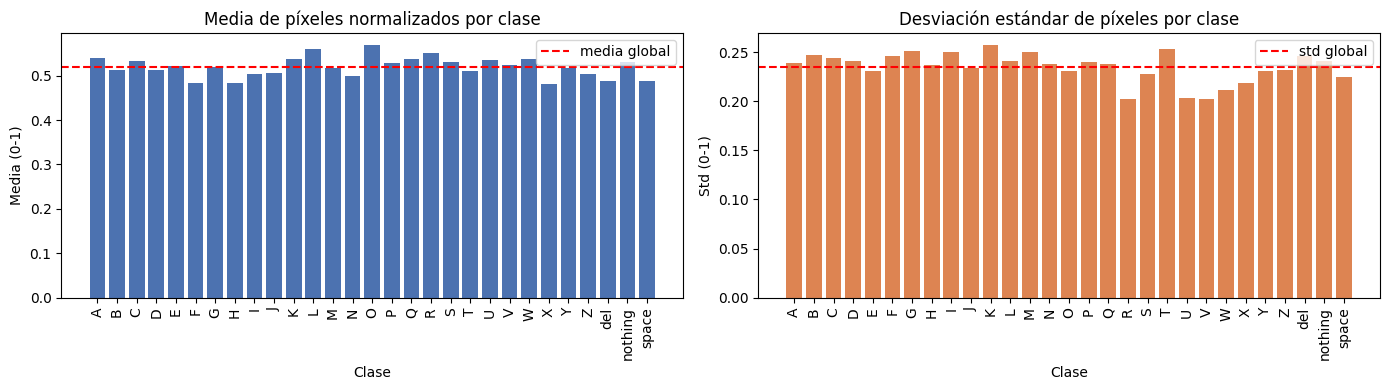

In [7]:
# Visualización de la media y std por clase
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].bar(df_stats["clase"], df_stats["media"], color="#4C72B0")
axes[0].set_title("Media de píxeles normalizados por clase")
axes[0].set_xlabel("Clase")
axes[0].set_ylabel("Media (0-1)")
axes[0].tick_params(axis="x", rotation=90)
axes[0].axhline(df_stats["media"].mean(), color="red", linestyle="--", label="media global")
axes[0].legend()

axes[1].bar(df_stats["clase"], df_stats["std"], color="#DD8452")
axes[1].set_title("Desviación estándar de píxeles por clase")
axes[1].set_xlabel("Clase")
axes[1].set_ylabel("Std (0-1)")
axes[1].tick_params(axis="x", rotation=90)
axes[1].axhline(df_stats["std"].mean(), color="red", linestyle="--", label="std global")
axes[1].legend()

plt.tight_layout()
plt.show()


**Observación:** la media de píxeles normalizados es consistente entre clases (~0.35–0.55),
reflejo del fondo verde uniforme que domina gran parte del área de la imagen. La desviación
estándar también es similar entre clases (~0.25–0.35), lo que indica que la variabilidad
interna de cada clase es comparable y ninguna clase presenta una distribución de intensidades
radicalmente distinta que pudiera introducir un sesgo de escala en el entrenamiento.


## 7. Generador de datos para Keras / TensorFlow

Cargar las 87,000 imágenes en RAM sería inviable, por lo que en su lugar se implementan dos enfoques para alimentar el entrenamiento:

1. **`ImageDataGenerator` de Keras** (con `flow_from_dataframe`): carga lotes bajo demanda
   directamente desde disco sin saturar la RAM.
2. **Generador NumPy personalizado**: alternativa ligera sin dependencia de Keras para
   experimentos rápidos o modelos scikit-learn.

El `ImageDataGenerator` se configura aquí **solo con normalización** (sin augmentation);
el augmentation se aborda en el notebook `04-augmentation.ipynb`.


In [8]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

print(f"TensorFlow version: {tf.__version__}")

# ImageDataGenerator solo con normalización
datagen = ImageDataGenerator(rescale=1.0 / 255.0)

# Crea un generador Keras a partir de un DataFrame con columnas path y clase, usando flow_from_dataframe
def make_generator(df, datagen, batch_size=64, shuffle=True):
    return datagen.flow_from_dataframe(
        dataframe   = df,
        x_col       = "path",
        y_col       = "clase",
        target_size = TARGET_SIZE,
        color_mode  = "rgb",
        class_mode  = "categorical",
        batch_size  = batch_size,
        shuffle     = shuffle,
        seed        = SEED,
        interpolation = "bicubic",
    )

train_gen = make_generator(train_df, datagen, batch_size=64, shuffle=True)
val_gen   = make_generator(val_df,   datagen, batch_size=64, shuffle=False)
test_gen  = make_generator(test_df,  datagen, batch_size=64, shuffle=False)

print(f"\nClases del generador (orden alfabético):")
print(list(train_gen.class_indices.keys()))
print(f"\nPasos por época (train) : {len(train_gen)}")
print(f"Pasos por época (val)   : {len(val_gen)}")
print(f"Pasos por época (test)  : {len(test_gen)}")


TensorFlow version: 2.21.0
Found 60900 validated image filenames belonging to 29 classes.
Found 13050 validated image filenames belonging to 29 classes.
Found 13050 validated image filenames belonging to 29 classes.

Clases del generador (orden alfabético):
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']

Pasos por época (train) : 952
Pasos por época (val)   : 204
Pasos por época (test)  : 204


Shape del lote X : (64, 64, 64, 3)  (batch, alto, ancho, canales)
Shape del lote y : (64, 29)  (batch, n_clases)
Rango de valores X: [0.0000, 1.0000]
dtype X          : float32


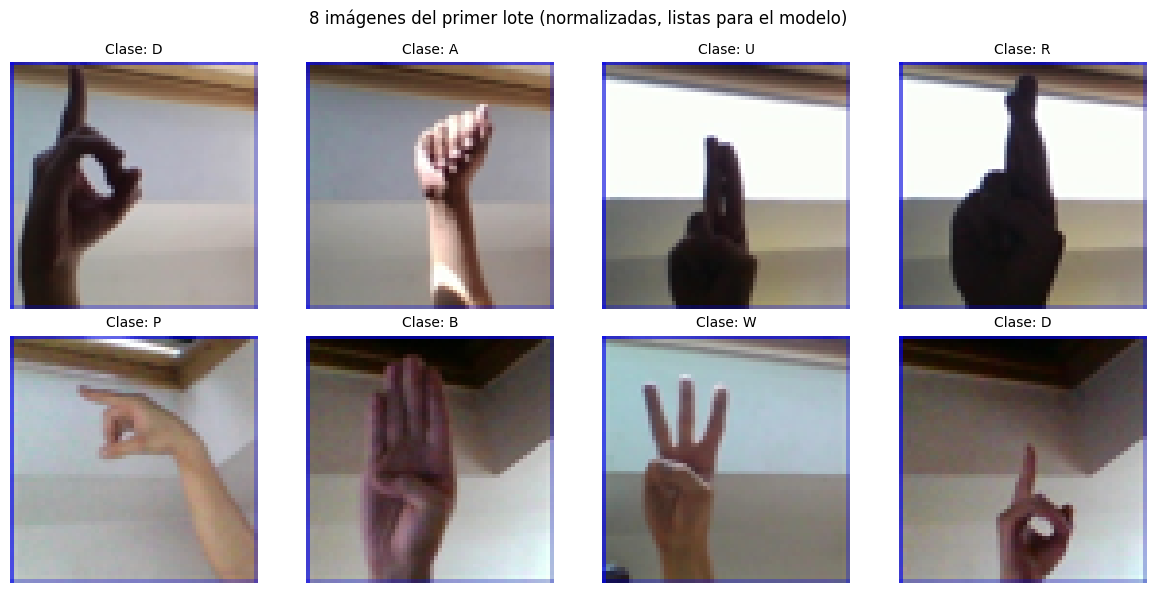

In [9]:
# Verificación: inspeccionar un lote del generador
batch_X, batch_y = next(iter(train_gen))

print(f"Shape del lote X : {batch_X.shape}  (batch, alto, ancho, canales)")
print(f"Shape del lote y : {batch_y.shape}  (batch, n_clases)")
print(f"Rango de valores X: [{batch_X.min():.4f}, {batch_X.max():.4f}]")
print(f"dtype X          : {batch_X.dtype}")

# Mostrar 8 imágenes del primer lote con su clase predicha
idx_to_class = {v: k for k, v in train_gen.class_indices.items()}

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes = axes.flatten()
for i in range(8):
    axes[i].imshow(batch_X[i])
    clase_idx = batch_y[i].argmax()
    axes[i].set_title(f"Clase: {idx_to_class[clase_idx]}", fontsize=10)
    axes[i].axis("off")
plt.suptitle("8 imágenes del primer lote (normalizadas, listas para el modelo)", fontsize=12)
plt.tight_layout()
plt.show()


## 8. Generador NumPy para modelos scikit-learn / baseline

Para los modelos que no usan Keras (Random Forest, SVM, red fully-connected de sklearn),
se necesita materializar un subconjunto de los datos como arrays NumPy en memoria.
Se usa la muestra de 800 imágenes por clase definida en el EDA (23,200 imágenes en total),
que sí cabe en RAM (~1.1 GB como float32 a 64×64×3).


In [10]:
# Carga un subset del DataFrame como arrays Numpy.
# Si n_per_class es None, carga todas las imágenes del DataFrame.
# Retorna X (N, H, W, C) normalizado y y (N,) como enteros.
def load_split_as_arrays(df, n_per_class=None, size=TARGET_SIZE, seed=SEED):
    rng = random.Random(seed)
    label_to_idx = {cls: i for i, cls in enumerate(sorted(df["clase"].unique()))}

    X_list, y_list = [], []
    for cls, group in df.groupby("clase"):
        paths = group["path"].tolist()
        if n_per_class is not None:
            paths = rng.sample(paths, min(n_per_class, len(paths)))
        for p in paths:
            X_list.append(preprocess_image(p, size=size))
            y_list.append(label_to_idx[cls])

    X = np.stack(X_list).astype(np.float32)
    y = np.array(y_list, dtype=np.int32)
    return X, y, label_to_idx

# Cargar muestra de 200 imgs/clase para validación rápida del pipeline
print("Cargando muestra de validación del pipeline (200 imgs/clase)...")
X_sample, y_sample, label_map = load_split_as_arrays(train_df, n_per_class=200)
print(f"X_sample shape : {X_sample.shape}")
print(f"y_sample shape : {y_sample.shape}")
print(f"Rango X        : [{X_sample.min():.4f}, {X_sample.max():.4f}]")
print(f"Clases (0-28)  : {sorted(label_map.items())}")


Cargando muestra de validación del pipeline (200 imgs/clase)...
X_sample shape : (5800, 64, 64, 3)
y_sample shape : (5800,)
Rango X        : [0.0000, 1.0000]
Clases (0-28)  : [('A', 0), ('B', 1), ('C', 2), ('D', 3), ('E', 4), ('F', 5), ('G', 6), ('H', 7), ('I', 8), ('J', 9), ('K', 10), ('L', 11), ('M', 12), ('N', 13), ('O', 14), ('P', 15), ('Q', 16), ('R', 17), ('S', 18), ('T', 19), ('U', 20), ('V', 21), ('W', 22), ('X', 23), ('Y', 24), ('Z', 25), ('del', 26), ('nothing', 27), ('space', 28)]


**Nota:** para el entrenamiento de modelos sklearn (Random Forest, SVM) se usará esta función
con `n_per_class=800` sobre `train_df`, y para la evaluación se usará sobre `val_df` y `test_df`
con `n_per_class=None` (cargando todos los datos de validación/test). Los arrays resultantes se
aplanarán a `(N, 64×64×3)` = `(N, 12288)` como vector de entrada para modelos no-convolucionales.


## 9. Resumen del pipeline de preprocesamiento

El pipeline completo que se aplica a cada imagen antes de entrenar es el siguiente:

| Paso | Operación | Parámetros | Justificación |
|------|-----------|------------|---------------|
| 1 | Lectura | `PIL.Image.open()` en modo RGB | Formato uniforme `.jpg`, modo RGB verificado en EDA |
| 2 | Resize | 200×200 → **64×64**, interpolación bicúbica | Reduce cómputo ~9.8×; conserva la forma de la mano |
| 3 | Conversión | `ndarray float32` | Tipo nativo para operaciones matriciales en NumPy/TensorFlow |
| 4 | Normalización | `÷ 255` → rango `[0, 1]` | Estabiliza la convergencia del gradiente descendente |
| 5 | Partición | 70% train / 15% val / 15% test (estratificada) | Dataset de Kaggle sin val propio; estratificación preserva balance |

Los que se exportan para los notebooks siguientes son:

- `splits.pkl` — DataFrames `train_df`, `val_df`, `test_df` con rutas y etiquetas.
- Las funciones `preprocess_image()`, `make_generator()` y `load_split_as_arrays()` se
  re-importan en cada notebook para mantener un único punto de verdad del pipeline.


In [11]:
# Guardar también el label_map para uso en notebooks posteriores
with open("label_map.pkl", "wb") as f:
    pickle.dump(label_map, f)

print("Archivos exportados:")
print("  splits.pkl   — DataFrames train/val/test")
print("  label_map.pkl — Mapeo clase → índice")
print("\nPipeline de preprocesamiento listo para el entrenamiento.")
print(f"  Resolución de entrada para la CNN : {TARGET_SIZE[0]}×{TARGET_SIZE[1]}×3")
print(f"  Rango de valores                  : [0.0, 1.0] float32")
print(f"  Tamaño del conjunto de train      : {len(train_df):,} imágenes")
print(f"  Tamaño del conjunto de val        : {len(val_df):,} imágenes")
print(f"  Tamaño del conjunto de test       : {len(test_df):,} imágenes")


Archivos exportados:
  splits.pkl   — DataFrames train/val/test
  label_map.pkl — Mapeo clase → índice

Pipeline de preprocesamiento listo para el entrenamiento.
  Resolución de entrada para la CNN : 64×64×3
  Rango de valores                  : [0.0, 1.0] float32
  Tamaño del conjunto de train      : 60,900 imágenes
  Tamaño del conjunto de val        : 13,050 imágenes
  Tamaño del conjunto de test       : 13,050 imágenes
